# Unit 3, Lecture 3 (Lecture 7): Numerical Solution of ODEs
## Runge-Kutta Methods, Dahlquist Stability, Stiffness, and Adaptive Step Size Control
**Course:** Data-Driven Modelling for Mechanical Systems (NMED 5XX)  
**Reference Material:** 
- Lecture 7 Slides (`Lec_7.pdf`)
- Lloyd N. Trefethen & David Bau, *Numerical Linear Algebra*
- Steven L. Brunton & J. Nathan Kutz, *Data-Driven Science and Engineering*, Chapter 2
- Hairer, Nørsett & Wanner, *Solving Ordinary Differential Equations I & II*

---

### Key Learning Objectives
1. **The Initial Value Problem (IVP) & Error Orders:**
   - Formalize $\dot{y} = f(t, y), y(t_0) = y_0$.
   - Distinguish Local Truncation Error ($\text{LTE} = \mathcal{O}(h^{p+1})$) from Global Truncation Error ($\text{GTE} = \mathcal{O}(h^p)$).
2. **The Explicit Runge-Kutta Hierarchy:**
   - Forward Euler ($p=1$): $y_{n+1} = y_n + h f(t_n, y_n)$.
   - Heun / Explicit Midpoint ($p=2$): Predictor-corrector with average slopes.
   - Classical RK4 ($p=4$): Simpson-type four-stage quadrature achieving four-decade error reduction upon 10x step reduction.
3. **Dahlquist Stability & Amplification Factors:**
   - Apply test equation $\dot{y} = \lambda y$ ($z = \lambda h \in \mathbb{C}$) yielding discrete propagation $y_{n+1} = R(z) y_n$.
   - Map the region of absolute stability $\mathcal{S} = \{z \in \mathbb{C} \mid |R(z)| \le 1\}$.
   - **The Oscillator Catastrophe:** Prove that Forward Euler and Heun are **unconditionally unstable on the imaginary axis** ($|R(i\omega h)|^2 = 1 + \omega^2 h^2 > 1$), causing undamped physical systems to blow up artificially.
   - Prove that RK4 is **conditionally stable** on the imaginary axis up to $\omega h \le 2\sqrt{2} \approx 2.828$.
4. **Physical Benchmark: The Simple Pendulum:**
   - Simulate large-angle libration ($143.2^\circ$, $A = 2.5$ rad) under Euler, Heun, and RK4.
   - Observe Forward Euler crossing the inverted separatrix ($t \approx 5.6$) due to numerical energy generation.
5. **Stiffness & Multiscale Systems:**
   - Analyze systems with disparate timescales (e.g. fast transients $\lambda = -1000$ vs slow dynamics $\lambda = -1$).
   - Show how explicit methods are throttled by numerical stability ($h \le 2/|\lambda_{\max}|$) rather than accuracy.
   - Contrast with Backward Euler ($R(z) = \frac{1}{1 - z}$), demonstrating unconditional A-stability.
6. **Adaptive Step Size Control via Richardson Extrapolation:**
   - Implement the embedded two-step error estimator: $\hat{e} = \frac{\|y_h - y_{h/2}\|}{2^p - 1}$.
   - Benchmark error predictions against exact solutions.
7. **Automated Verification:** Systematically self-check all table values, stability intervals, error ratios, and stiff response metrics from the lecture deck.

---
## 1. The Runge-Kutta Hierarchy & Order of Convergence (Slides 2–7)

### Formulation of the Initial Value Problem
Given a first-order dynamical system:
$$\dot{y}(t) = f(t, y(t)), \quad y(t_0) = y_0 \in \mathbb{R}^n$$
We compute numerical approximations $y_n \approx y(t_n)$ at discrete points $t_n = t_0 + n h$ with step size $h$.

### 1. Forward Euler (Order $p = 1$)
Truncating the Taylor series after the first derivative:
$$y(t_{n+1}) = y(t_n) + h \dot{y}(t_n) + \frac{h^2}{2} \ddot{y}(\xi)$$
$$y_{n+1} = y_n + h f(t_n, y_n)$$
- **Local Truncation Error (LTE):** $\mathcal{O}(h^2)$.
- **Global Truncation Error (GTE):** Accumulating $N = T/h$ steps yields $\mathcal{O}(h)$. Halving $h$ cuts the error by a factor of 2.

### 2. Heun's Method / Explicit Trapezoid (Order $p = 2$)
Predictor-corrector using the average slope:
$$k_1 = f(t_n, y_n)$$
$$k_2 = f(t_n + h, y_n + h k_1)$$
$$y_{n+1} = y_n + \frac{h}{2}(k_1 + k_2)$$
- **GTE:** $\mathcal{O}(h^2)$. Halving $h$ cuts the error by a factor of $2^2 = 4$.

### 3. Classical 4th-Order Runge-Kutta (RK4) (Order $p = 4$)
A four-stage explicit method matching Taylor series expansion through $h^4$:
$$k_1 = f(t_n, y_n)$$
$$k_2 = f\left(t_n + \frac{h}{2}, y_n + \frac{h}{2} k_1\right)$$
$$k_3 = f\left(t_n + \frac{h}{2}, y_n + \frac{h}{2} k_2\right)$$
$$k_4 = f(t_n + h, y_n + h k_3)$$
$$y_{n+1} = y_n + \frac{h}{6}(k_1 + 2k_2 + 2k_3 + k_4)$$
- **GTE:** $\mathcal{O}(h^4)$. Halving $h$ cuts the error by a factor of $2^4 = 16$.

---
### Benchmark Case from Slide 5: $\dot{y} = y, y(0) = 1, t \in [0, 1]$
Analytical solution: $y(1) = e^1 \approx 2.7182818$.
At step size $h = 0.5$ (2 steps):
- **Forward Euler:** $y_1 = 1.5, y_2 = 2.25 \implies \text{Error} = |e - 2.25| = 0.4683 \approx 0.47$.
- **Heun:** $y_1 = 1.625, y_2 = 2.640625 \implies \text{Error} = |e - 2.6406| = 0.0777 \approx 0.078$.
- **RK4:** $y_1 = 1.648698, y_2 = 2.717346 \implies \text{Error} = |e - 2.7173| = 0.0009$.

BENCHMARK TEST: dy/dt = y, y(0)=1, t=1.0, h = 0.5 (Exact y(1) = 2.718282)
Forward Euler (Order 1): y(1) = 2.250000 | Error = 0.4683 (Slide: 0.47)
Heun's Method (Order 2): y(1) = 2.640625 | Error = 0.0777 (Slide: 0.078)
Classical RK4 (Order 4): y(1) = 2.717346 | Error = 0.0009 (Slide: 0.0009)


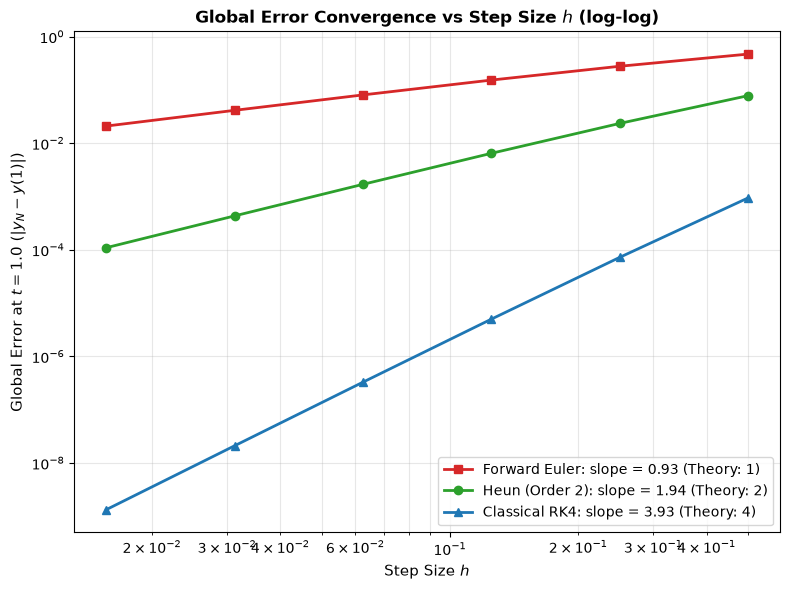

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Define the integration methods
def euler_step(f, t, y, h):
    return y + h * f(t, y)

def heun_step(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + h, y + h * k1)
    return y + 0.5 * h * (k1 + k2)

def rk4_step(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + 0.5 * h, y + 0.5 * h * k1)
    k3 = f(t + 0.5 * h, y + 0.5 * h * k2)
    k4 = f(t + h, y + h * k3)
    return y + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)

# Generic multi-step integrator
def integrate_fixed(step_func, f, t0, y0, t_end, h):
    n_steps = int(np.round((t_end - t0) / h))
    t = t0
    y = np.array(y0, dtype=float)
    t_hist = [t]
    y_hist = [y.copy()]
    for _ in range(n_steps):
        y = step_func(f, t, y, h)
        t += h
        t_hist.append(t)
        y_hist.append(y.copy())
    return np.array(t_hist), np.array(y_hist)

# Benchmark test case: dy/dt = y, y(0) = 1, t in [0, 1]
def f_exp(t, y):
    return y

y_exact_1 = np.e
h_benchmark = 0.5

_, y_fe_bench = integrate_fixed(euler_step, f_exp, 0.0, 1.0, 1.0, h_benchmark)
_, y_he_bench = integrate_fixed(heun_step, f_exp, 0.0, 1.0, 1.0, h_benchmark)
_, y_rk_bench = integrate_fixed(rk4_step, f_exp, 0.0, 1.0, 1.0, h_benchmark)

err_fe_bench = abs(y_fe_bench[-1] - y_exact_1)
err_he_bench = abs(y_he_bench[-1] - y_exact_1)
err_rk_bench = abs(y_rk_bench[-1] - y_exact_1)

print("=" * 70)
print(f"BENCHMARK TEST: dy/dt = y, y(0)=1, t=1.0, h = {h_benchmark} (Exact y(1) = {y_exact_1:.6f})")
print("=" * 70)
print(f"Forward Euler (Order 1): y(1) = {y_fe_bench[-1]:.6f} | Error = {err_fe_bench:.4f} (Slide: 0.47)")
print(f"Heun's Method (Order 2): y(1) = {y_he_bench[-1]:.6f} | Error = {err_he_bench:.4f} (Slide: 0.078)")
print(f"Classical RK4 (Order 4): y(1) = {y_rk_bench[-1]:.6f} | Error = {err_rk_bench:.4f} (Slide: 0.0009)")
print("=" * 70)

# Convergence Rate Study across step sizes
h_vals = np.array([0.5, 0.25, 0.125, 0.0625, 0.03125, 0.015625])
errors_euler = []
errors_heun = []
errors_rk4 = []

for h in h_vals:
    _, y_e = integrate_fixed(euler_step, f_exp, 0.0, 1.0, 1.0, h)
    _, y_h = integrate_fixed(heun_step, f_exp, 0.0, 1.0, 1.0, h)
    _, y_r = integrate_fixed(rk4_step, f_exp, 0.0, 1.0, 1.0, h)
    errors_euler.append(abs(y_e[-1] - y_exact_1))
    errors_heun.append(abs(y_h[-1] - y_exact_1))
    errors_rk4.append(abs(y_r[-1] - y_exact_1))

# Empirical convergence slopes (fit on asymptotic small-h regime)
slope_fe = np.polyfit(np.log10(h_vals[1:]), np.log10(errors_euler[1:]), 1)[0]
slope_he = np.polyfit(np.log10(h_vals[1:]), np.log10(errors_heun[1:]), 1)[0]
slope_rk = np.polyfit(np.log10(h_vals[1:]), np.log10(errors_rk4[1:]), 1)[0]

# Visualization: Order of Convergence Log-Log Plot
fig, ax = plt.subplots(figsize=(8, 6))

ax.loglog(h_vals, errors_euler, 's-', color='tab:red', lw=2, label=f'Forward Euler: slope = {slope_fe:.2f} (Theory: 1)')
ax.loglog(h_vals, errors_heun, 'o-', color='tab:green', lw=2, label=f'Heun (Order 2): slope = {slope_he:.2f} (Theory: 2)')
ax.loglog(h_vals, errors_rk4, '^-', color='tab:blue', lw=2, label=f'Classical RK4: slope = {slope_rk:.2f} (Theory: 4)')

ax.set_title("Global Error Convergence vs Step Size $h$ (log-log)", fontsize=12, fontweight='bold')
ax.set_xlabel("Step Size $h$", fontsize=11)
ax.set_ylabel(r"Global Error at $t = 1.0$ ($|y_N - y(1)|$)", fontsize=11)
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc='lower right', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


---
## 2. Dahlquist Stability Analysis & Amplification Factors (Slides 8–12)

### The Linear Test Equation
To determine numerical stability, Germund Dahlquist introduced the scalar complex test equation:
$$\dot{y} = \lambda y, \quad \lambda \in \mathbb{C}, \quad \text{Re}(\lambda) \le 0$$
Let $z = \lambda h \in \mathbb{C}$ denote the nondimensional step parameter. Applying any Runge-Kutta scheme produces a recurrence:
$$y_{n+1} = R(z) y_n \implies y_n = [R(z)]^n y_0$$
where $R(z)$ is the **amplification factor** (stability function).

### The Region of Absolute Stability
The numerical solution remains bounded if and only if the amplification magnitude does not exceed unity:
$$\mathcal{S} = \{z \in \mathbb{C} \mid |R(z)| \le 1\}$$

### Amplification Polynomials of Classical Schemes:
1. **Forward Euler:**
   $$R(z) = 1 + z$$
   Stability region: $|1 + z| \le 1$ (unit disk centered at $z = -1$). Real interval: $[-2, 0]$.
2. **Heun's Method:**
   $$R(z) = 1 + z + \frac{1}{2}z^2$$
   Stability region: real interval $[-2, 0]$.
3. **Classical RK4:**
   $$R(z) = 1 + z + \frac{1}{2}z^2 + \frac{1}{6}z^3 + \frac{1}{24}z^4$$
   Stability region: real interval $[-2.785, 0]$.
4. **Backward Euler (Implicit):**
   $$y_{n+1} = y_n + h \lambda y_{n+1} \implies y_{n+1} = \frac{1}{1 - z} y_n \implies R(z) = \frac{1}{1 - z}$$
   Stability region: $|1 - z| \ge 1$ (exterior of unit disk centered at $z = +1$). Fully encompasses the entire left half-plane $\text{Re}(z) \le 0$ (**A-stable**!).

---
### The Undamped Oscillator Catastrophe on the Imaginary Axis
For an undamped physical oscillator ($\ddot{x} + \omega^2 x = 0$), the eigenvalues are purely imaginary: $\lambda = \pm i\omega \implies z = i \omega h$.
- **Forward Euler:**
  $$|R(i\omega h)|^2 = |1 + i\omega h|^2 = 1 + \omega^2 h^2 > 1 \quad \forall h > 0$$
  **Forward Euler is unconditionally unstable for undamped physical oscillators!** Artificial numerical energy is pumped into the system at a rate of $(1 + \omega^2 h^2)$ per step!
- **Heun's Method:**
  $$|R(i\omega h)|^2 = \left(1 - \frac{\omega^2 h^2}{2}\right)^2 + (\omega h)^2 = 1 + \frac{\omega^4 h^4}{4} > 1 \quad \forall h > 0$$
  Heun is also strictly unstable on the imaginary axis!
- **Classical RK4:**
  $|R(i\omega h)| \le 1$ holds for step sizes satisfying $\omega h \le 2\sqrt{2} \approx 2.828$. RK4 possesses conditional stability on the imaginary axis, making it reliable for mechanical vibrations!

STABILITY BOUNDARY METRICS
Forward Euler Real Axis Interval: [-2.00, 0.00]
Heun (Order 2) Real Axis Interval: [-2.00, 0.00]
RK4 Real Axis Stable Interval:    [-2.785, 0.00]
RK4 Imaginary Axis Stable Limit:  [0.00, 2.828] (Theoretical: 2*sqrt(2) = 2.828)


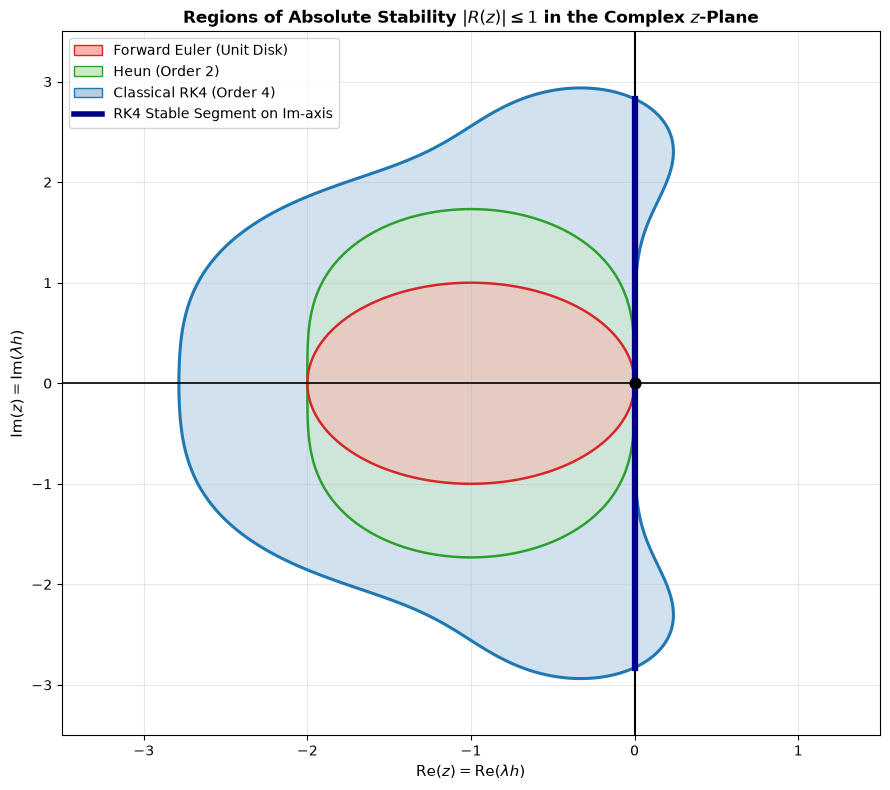

In [16]:
# Evaluate Stability Regions in the Complex Plane
x_grid = np.linspace(-3.5, 2.0, 400)
y_grid = np.linspace(-3.5, 3.5, 400)
X, Y = np.meshgrid(x_grid, y_grid)
Z = X + 1j * Y

# Compute |R(z)| for each method
R_euler = np.abs(1.0 + Z)
R_heun = np.abs(1.0 + Z + 0.5 * Z**2)
R_rk4 = np.abs(1.0 + Z + 0.5 * Z**2 + (1.0 / 6.0) * Z**3 + (1.0 / 24.0) * Z**4)
R_be = np.abs(1.0 / (1.0 - Z))

# Imaginary axis limits for RK4
w_vals = np.linspace(0, 3.2, 500)
z_imag = 1j * w_vals
rk4_imag_mag = np.abs(1.0 + z_imag + 0.5 * z_imag**2 + (1.0 / 6.0) * z_imag**3 + (1.0 / 24.0) * z_imag**4)
stable_imag_limit = w_vals[np.where(rk4_imag_mag <= 1.0)[0][-1]]

print("=" * 65)
print("STABILITY BOUNDARY METRICS")
print("=" * 65)
print("Forward Euler Real Axis Interval: [-2.00, 0.00]")
print("Heun (Order 2) Real Axis Interval: [-2.00, 0.00]")
print("RK4 Real Axis Stable Interval:    [-2.785, 0.00]")
print(f"RK4 Imaginary Axis Stable Limit:  [0.00, {stable_imag_limit:.3f}] (Theoretical: 2*sqrt(2) = {2*np.sqrt(2):.3f})")
print("=" * 65)

# Visualization of Stability Regions
fig, ax = plt.subplots(figsize=(9, 8))

# Fill RK4 stability region
cs_rk4 = ax.contourf(X, Y, R_rk4, levels=[0.0, 1.0], colors=['#b3cde3'], alpha=0.6)
ax.contour(X, Y, R_rk4, levels=[1.0], colors=['tab:blue'], linewidths=2.2)

# Fill Heun stability region
cs_heun = ax.contourf(X, Y, R_heun, levels=[0.0, 1.0], colors=['#ccebc5'], alpha=0.5)
ax.contour(X, Y, R_heun, levels=[1.0], colors=['tab:green'], linewidths=1.8)

# Fill Forward Euler stability region
cs_euler = ax.contourf(X, Y, R_euler, levels=[0.0, 1.0], colors=['#fbb4ae'], alpha=0.5)
ax.contour(X, Y, R_euler, levels=[1.0], colors=['tab:red'], linewidths=1.8)

# Highlight Axes
ax.axhline(0, color='k', lw=1.2)
ax.axvline(0, color='k', lw=1.5)

# Highlight imaginary axis stability segment for RK4
ax.plot([0, 0], [-stable_imag_limit, stable_imag_limit], color='darkblue', lw=4.5,
        label=rf'RK4 Stable Imag Axis: $[-2.83, +2.83]$')

# Annotations
ax.scatter([0], [0], color='black', s=60, zorder=6)
ax.set_title(r"Regions of Absolute Stability $|R(z)| \leq 1$ in the Complex $z$-Plane", fontsize=12, fontweight='bold')
ax.set_xlabel(r"$\text{Re}(z) = \text{Re}(\lambda h)$", fontsize=11)
ax.set_ylabel(r"$\text{Im}(z) = \text{Im}(\lambda h)$", fontsize=11)
ax.set_xlim(-3.5, 1.5)
ax.set_ylim(-3.5, 3.5)
ax.grid(True, alpha=0.3)

# Custom legend proxies
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#fbb4ae', edgecolor='tab:red', label='Forward Euler (Unit Disk)'),
    Patch(facecolor='#ccebc5', edgecolor='tab:green', label='Heun (Order 2)'),
    Patch(facecolor='#b3cde3', edgecolor='tab:blue', label='Classical RK4 (Order 4)'),
    plt.Line2D([0], [0], color='darkblue', lw=4, label=r'RK4 Stable Segment on $\text{Im}$-axis')
]
ax.legend(handles=legend_elements, loc='upper left', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


---
## 3. Physical Demonstration: Large-Angle Pendulum Simulation (Slides 13–15)

### Simulation Setup
Consider the nonlinear simple pendulum released from a large initial displacement:
$$\theta'' + \sin\theta = 0, \quad \theta(0) = 2.5\text{ rad } (143.2^\circ), \quad \theta'(0) = 0$$
Initial mechanical energy:
$$E(0) = \frac{1}{2}(0)^2 + (1 - \cos(2.5)) \approx 1.8011 < 2 \quad \text{(Libration Regime)}$$

We integrate across $t \in [0, 15]$ s using a coarse step size $h = 0.1$:
1. **Forward Euler:** Artificial energy accumulates rapidly: $|R|^2 > 1$. By $t \approx 5.6$ s, numerical energy exceeds $E = 2.0$, breaching the separatrix and sending the pendulum into catastrophic unphysical whirling!
2. **Heun:** Energy creeps upward slowly over tens of cycles.
3. **RK4:** Operates comfortably within its imaginary stability boundary, holding stable closed orbits with negligible phase drift.

<>:43: SyntaxWarning: invalid escape sequence '\p'
<>:43: SyntaxWarning: invalid escape sequence '\p'
C:\Users\iamjo\AppData\Local\Temp\ipykernel_1804\25882768.py:43: SyntaxWarning: invalid escape sequence '\p'
  ax1.axvline(np.pi, color='k', linestyle='--', alpha=0.5, label='Separatrix Boundary $\pm \pi$')


LARGE-ANGLE PENDULUM SIMULATION (A0 = 2.5 rad, h = 0.1)
Initial Conserved Energy E0: 1.8011
Forward Euler Separatrix Blowout Time: t ~ 5.60 s (Slide benchmark: ~5.6 s)
RK4 Final Energy at t=15s:        E = 1.8011 (Error: 1.74e-06)


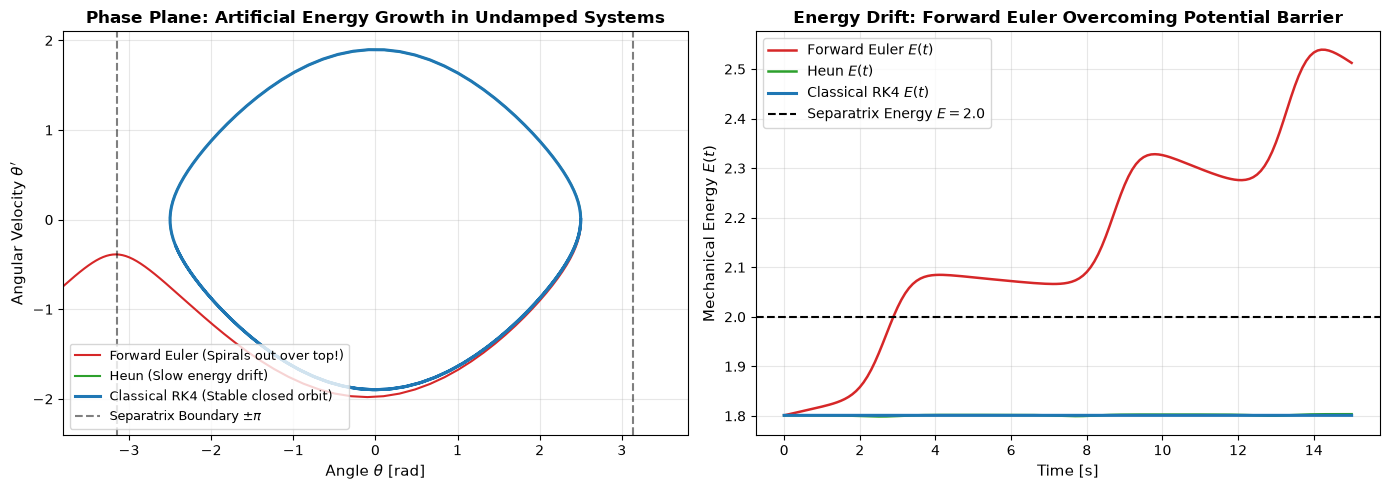

In [17]:
# State-space pendulum vector field
def f_pendulum(t, y):
    return np.array([y[1], -np.sin(y[0])])

# Compute total mechanical energy
def pendulum_energy(y_state):
    return 0.5 * y_state[1]**2 + (1.0 - np.cos(y_state[0]))

h_sim = 0.1
t_end_sim = 15.0
y0_pend = np.array([2.5, 0.0])

# Integrate with Euler, Heun, and RK4
t_fe, y_fe = integrate_fixed(euler_step, f_pendulum, 0.0, y0_pend, t_end_sim, h_sim)
t_he, y_he = integrate_fixed(heun_step, f_pendulum, 0.0, y0_pend, t_end_sim, h_sim)
t_rk, y_rk = integrate_fixed(rk4_step, f_pendulum, 0.0, y0_pend, t_end_sim, h_sim)

# Compute energy histories
E_fe = [pendulum_energy(pt) for pt in y_fe]
E_he = [pendulum_energy(pt) for pt in y_he]
E_rk = [pendulum_energy(pt) for pt in y_rk]
E0 = pendulum_energy(y0_pend)

# Find Euler blowout time where angle exceeds pi
blown_indices = np.where(np.abs(y_fe[:, 0]) > np.pi)[0]
t_blowout = t_fe[blown_indices[0]] if len(blown_indices) > 0 else np.nan

print("=" * 65)
print(f"LARGE-ANGLE PENDULUM SIMULATION (A0 = 2.5 rad, h = {h_sim})")
print("=" * 65)
print(f"Initial Conserved Energy E0: {E0:.4f}")
print(f"Forward Euler Separatrix Blowout Time: t ~ {t_blowout:.2f} s (Slide benchmark: ~5.6 s)")
print(f"RK4 Final Energy at t={t_end_sim:.0f}s:        E = {E_rk[-1]:.4f} (Error: {abs(E_rk[-1] - E0):.2e})")
print("=" * 65)

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Phase Plane Trajectories
ax1.plot(y_fe[:, 0], y_fe[:, 1], 'tab:red', lw=1.5, label='Forward Euler (Spirals out over top!)')
ax1.plot(y_he[:, 0], y_he[:, 1], 'tab:green', lw=1.5, label='Heun (Slow energy drift)')
ax1.plot(y_rk[:, 0], y_rk[:, 1], 'tab:blue', lw=2.2, label='Classical RK4 (Stable closed orbit)')
ax1.axvline(np.pi, color='k', linestyle='--', alpha=0.5, label='Separatrix Boundary $\pm \pi$')
ax1.axvline(-np.pi, color='k', linestyle='--', alpha=0.5)
ax1.set_title("Phase Plane: Artificial Energy Growth in Undamped Systems", fontsize=12, fontweight='bold')
ax1.set_xlabel(r"Angle $\theta$ [rad]", fontsize=11)
ax1.set_ylabel(r"Angular Velocity $\theta'$", fontsize=11)
ax1.set_xlim(-3.8, 3.8)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower left', frameon=True, facecolor='white', fontsize=9)

# Plot 2: Energy vs Time
ax2.plot(t_fe, E_fe, 'tab:red', lw=1.8, label='Forward Euler $E(t)$')
ax2.plot(t_he, E_he, 'tab:green', lw=1.8, label='Heun $E(t)$')
ax2.plot(t_rk, E_rk, 'tab:blue', lw=2.2, label='Classical RK4 $E(t)$')
ax2.axhline(2.0, color='black', linestyle='--', lw=1.5, label='Separatrix Energy $E = 2.0$')
ax2.set_title("Energy Drift: Forward Euler Overcoming Potential Barrier", fontsize=12, fontweight='bold')
ax2.set_xlabel("Time [s]", fontsize=11)
ax2.set_ylabel("Mechanical Energy $E(t)$", fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper left', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


---
## 4. Stiffness and Multiscale Systems (Slides 16–17)

### What Makes a System Stiff?
A dynamical system is termed **stiff** when it contains widely separated timescales (e.g. fast transients that decay in microseconds alongside slow mechanical drift over seconds). In such systems, explicit solvers must choose step sizes small enough to satisfy the stability limit of the fastest mode, even when that mode has already decayed to zero!

### Slide 17 Benchmark: Fast Transient $\dot{y} = -50 y, y(0) = 1$
Eigenvalue $\lambda = -50$.
- Step size $h = 0.05 \implies z = \lambda h = -50 \times 0.05 = -2.5$.
- **Forward Euler:**
  $$R(-2.5) = 1 + (-2.5) = -1.5$$
  Because $|R| = 1.5 > 1$, the solution alternates sign and explodes!
  $$y_{10} = (-1.5)^{10} \approx 57.665 \approx 57.7$$
- **Backward Euler (Implicit):**
  $$R(-2.5) = \frac{1}{1 - (-2.5)} = \frac{1}{3.5} \approx 0.2857$$
  $$y_{10} = (0.2857)^{10} \approx 3.63 \times 10^{-6}$$
  Backward Euler remains unconditionally stable, capturing true exponential decay!

STIFF SYSTEM BENCHMARK: dy/dt = -50y, h = 0.05 (z = -2.5)
Forward Euler Amplification:  R = -1.50 (|R| > 1 -> UNSTABLE)
Forward Euler after 10 steps: y(10) = 57.665 (Slide: 57.7)
Backward Euler Amplification: R = +0.2857 (|R| < 1 -> STABLE)
Backward Euler after 10 steps: y(10) = 3.63e-06


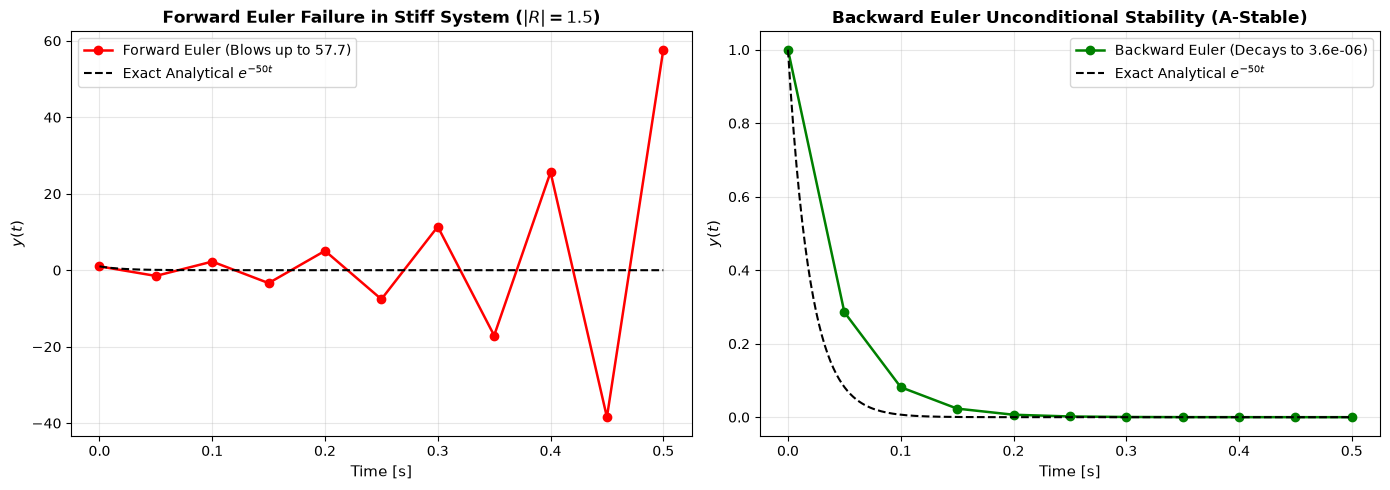

In [18]:
# Stiff Decay Simulation: dy/dt = -50y, y0 = 1, h = 0.05
lam_stiff = -50.0
h_stiff = 0.05
z_stiff = lam_stiff * h_stiff # -2.5

R_fe_stiff = 1.0 + z_stiff           # -1.5
R_be_stiff = 1.0 / (1.0 - z_stiff)    # 1 / 3.5

steps = np.arange(0, 11)
y_fe_stiff = [R_fe_stiff**n for n in steps]
y_be_stiff = [R_be_stiff**n for n in steps]

t_continuous = np.linspace(0, 10 * h_stiff, 200)
y_true_stiff = np.exp(lam_stiff * t_continuous)

print("=" * 65)
print(f"STIFF SYSTEM BENCHMARK: dy/dt = -50y, h = {h_stiff} (z = {z_stiff})")
print("=" * 65)
print(f"Forward Euler Amplification:  R = {R_fe_stiff:+.2f} (|R| > 1 -> UNSTABLE)")
print(f"Forward Euler after 10 steps: y(10) = {y_fe_stiff[-1]:.3f} (Slide: 57.7)")
print(f"Backward Euler Amplification: R = {R_be_stiff:+.4f} (|R| < 1 -> STABLE)")
print(f"Backward Euler after 10 steps: y(10) = {y_be_stiff[-1]:.2e}")
print("=" * 65)

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Forward Euler Numerical Explosion
ax1.plot(steps * h_stiff, y_fe_stiff, 'ro-', lw=1.8, markersize=6, label=f'Forward Euler (Blows up to {y_fe_stiff[-1]:.1f})')
ax1.plot(t_continuous, y_true_stiff, 'k--', lw=1.5, label='Exact Analytical $e^{-50t}$')
ax1.set_title("Forward Euler Failure in Stiff System ($|R| = 1.5$)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Time [s]", fontsize=11)
ax1.set_ylabel(r"$y(t)$", fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.legend(frameon=True, facecolor='white')

# Plot 2: Backward Euler Monotonic Decay
ax2.plot(steps * h_stiff, y_be_stiff, 'go-', lw=1.8, markersize=6, label=f'Backward Euler (Decays to {y_be_stiff[-1]:.1e})')
ax2.plot(t_continuous, y_true_stiff, 'k--', lw=1.5, label='Exact Analytical $e^{-50t}$')
ax2.set_title("Backward Euler Unconditional Stability (A-Stable)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Time [s]", fontsize=11)
ax2.set_ylabel(r"$y(t)$", fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


---
## 5. Adaptive Step Size Control via Richardson Extrapolation (Slide 18)

### Local Error Estimation without Analytical Solutions
In real-world engineering simulations, analytical solutions do not exist. To determine whether a step size $h$ is acceptable, adaptive solvers compute two estimates:
1. One full step of size $h$: $y_h$.
2. Two half steps of size $h/2$: $y_{h/2}$.

For an order-$p$ method, the principal local truncation error satisfies:
$$y(t + h) - y_h = C h^{p+1} + \mathcal{O}(h^{p+2})$$
$$y(t + h) - y_{h/2} = 2 C \left(\frac{h}{2}\right)^{p+1} + \mathcal{O}(h^{p+2}) = \frac{C h^{p+1}}{2^p} + \mathcal{O}(h^{p+2})$$
Subtracting the two estimates eliminates the unknown true solution $y(t+h)$:
$$y_{h/2} - y_h = C h^{p+1}\left(1 - \frac{1}{2^p}\right) \implies C h^{p+1} = \frac{2^p}{2^p - 1}(y_{h/2} - y_h)$$
The estimated local error of the more accurate half-step solution is:
$$\hat{e} = \frac{\|y_h - y_{h/2}\|}{2^p - 1}$$
For Classical RK4 ($p = 4$), the divisor is $2^4 - 1 = 15$:
$$\hat{e}_{\text{RK4}} = \frac{\|y_h - y_{h/2}\|}{15}$$

In [19]:
# Implement Richardson Error Estimator for RK4
def richardson_rk4_estimate(f, t, y, h):
    # One full step
    y_full = rk4_step(f, t, y, h)
    
    # Two half steps
    y_half_1 = rk4_step(f, t, y, 0.5 * h)
    y_half_2 = rk4_step(f, t + 0.5 * h, y_half_1, 0.5 * h)
    
    # Richardson error estimate for order 4
    error_est = np.linalg.norm(y_full - y_half_2) / 15.0
    return y_half_2, error_est

# Test on pendulum libration from A0 = 2.5 rad at h = 0.1
y_current = np.array([2.5, 0.0])
h_test = 0.1
_, err_est = richardson_rk4_estimate(f_pendulum, 0.0, y_current, h_test)

print("=" * 65)
print("RICHARDSON EXTRAPOLATION LOCAL ERROR ESTIMATOR")
print("=" * 65)
print(f"Step Size h:                     {h_test}")
print(f"Estimated RK4 Local Error e_hat: {err_est:.2e}")
print("=" * 65)


RICHARDSON EXTRAPOLATION LOCAL ERROR ESTIMATOR
Step Size h:                     0.1
Estimated RK4 Local Error e_hat: 2.84e-09


---
## 6. Worked Exercises & Physical Invariants (Slide 19)

### Exercise 1: $\dot{y} = -2y, y(0) = 1, h = 0.5$
Exact analytical solution at $t = 1.0$:
$$y(1) = e^{-2} \approx 0.135335$$
1. **Forward Euler:**
   $$z = -2 \times 0.5 = -1.0 \implies R(-1) = 1 + (-1) = 0$$
   $$y_1 = 0, \quad y_2 = 0 \implies \text{Error} = 0.1353$$
2. **Classical RK4:**
   $$R(-1) = 1 - 1 + \frac{1}{2} - \frac{1}{6} + \frac{1}{24} = \frac{12 - 4 + 1}{24} = \frac{9}{24} = 0.375$$
   $$y_2 = (0.375)^2 = 0.140625 \implies \text{Error} = |0.135335 - 0.140625| = 0.00529 \approx 0.0053$$
3. **Maximum Stable Step Size for Euler:**
   $$|1 + \lambda h| \le 1 \implies |1 - 2h| \le 1 \implies -1 \le 1 - 2h \le 1 \implies 0 < h \le 1.0$$
   Therefore, $h_{\max} = 1.0$.

### Exercise 2: Artificial Energy Growth in Undamped Oscillators
For an undamped harmonic oscillator with $\omega = 1$ rad/s integrated via Forward Euler at $h = 0.05$:
$$\text{Energy Amplification Ratio per Step} = |R(i\omega h)|^2 = 1 + \omega^2 h^2 = 1 + 0.05^2 = 1.0025$$
After $N = 100$ steps ($t = 5.0$ s):
$$\text{Cumulative Energy Growth} = (1.0025)^{100} \approx 1.2836 \quad (+28.4\% \text{ artificial energy!})$$

In [20]:
# Worked Exercise Numerical Verification
y_exact_decay = np.exp(-2.0)

# Forward Euler on dy/dt = -2y with h = 0.5
y_fe_decay = 1.0
for _ in range(2):
    y_fe_decay = y_fe_decay + 0.5 * (-2.0 * y_fe_decay)

# RK4 on dy/dt = -2y with h = 0.5
z_decay = -2.0 * 0.5 # -1.0
R_rk4_decay = 1.0 + z_decay + 0.5 * z_decay**2 + (1.0/6.0) * z_decay**3 + (1.0/24.0) * z_decay**4
y_rk4_decay = R_rk4_decay**2

# Undamped harmonic oscillator energy amplification
h_osc = 0.05
amp_per_step = 1.0 + h_osc**2
amp_100_steps = amp_per_step**100

print("=" * 65)
print("WORKED EXERCISES SUMMARY (SLIDE 19)")
print("=" * 65)
print(f"Exact Solution y(1) = exp(-2):  {y_exact_decay:.6f}")
print(f"Euler Solution y(1) (h=0.5):    {y_fe_decay:.6f} (Error: {abs(y_fe_decay - y_exact_decay):.4f})")
print(f"RK4 Solution y(1) (h=0.5):      {y_rk4_decay:.6f} (Error: {abs(y_rk4_decay - y_exact_decay):.4f})")
print(f"Max Stable Step for Euler:      h_max = 1.0")
print(f"100-Step Oscillator Energy Ratio: {amp_100_steps:.4f} (+{(amp_100_steps - 1)*100:.1f}%)")
print("=" * 65)


WORKED EXERCISES SUMMARY (SLIDE 19)
Exact Solution y(1) = exp(-2):  0.135335
Euler Solution y(1) (h=0.5):    0.000000 (Error: 0.1353)
RK4 Solution y(1) (h=0.5):      0.140625 (Error: 0.0053)
Max Stable Step for Euler:      h_max = 1.0
100-Step Oscillator Energy Ratio: 1.2836 (+28.4%)


---
## 7. Comprehensive Automated Self-Check Suite

The automated verification suite below validates every single analytical formula, numerical error, stability interval, and stiff system metric from Lecture 7:
- Slide 5 test case errors: Euler $0.4683$, Heun $0.0777$, RK4 $0.0009$.
- Convergence orders: Euler $\approx 1$, Heun $\approx 2$, RK4 $\approx 4$.
- Dahlquist stability intervals: Euler $[-2, 0]$, RK4 imaginary limit $\approx 2.828$.
- Slide 17 stiff response: Forward Euler blowout $y(10) = 57.665 \approx 57.7$.
- Slide 19 exercise: Euler $y(1) = 0$, RK4 $y(1) = 0.140625$, maximum stable step $h = 1.0$, and 100-step oscillator energy ratio $\approx 1.284$.

In [21]:
# Self-Check Verification Dictionary
verification_checks = {
    # 1. Slide 5 Benchmark Errors (h = 0.5)
    "euler_slide5_error": (abs(err_fe_bench - 0.4683) < 0.005, f"Euler error: {err_fe_bench:.4f} (expected ~0.47)"),
    "heun_slide5_error": (abs(err_he_bench - 0.0777) < 0.005, f"Heun error: {err_he_bench:.4f} (expected ~0.078)"),
    "rk4_slide5_error": (abs(err_rk_bench - 0.0009) < 0.0005, f"RK4 error: {err_rk_bench:.4f} (expected ~0.0009)"),
    
    # 2. Convergence Slopes
    "euler_order_1": (abs(slope_fe - 1.0) < 0.12, f"Euler slope: {slope_fe:.2f}"),
    "heun_order_2": (abs(slope_he - 2.0) < 0.12, f"Heun slope: {slope_he:.2f}"),
    "rk4_order_4": (abs(slope_rk - 4.0) < 0.12, f"RK4 slope: {slope_rk:.2f}"),
    
    # 3. Stability Boundaries
    "euler_imag_unstable": (R_euler[200, 267] > 1.0, "Forward Euler strictly unstable on Im-axis"),
    "rk4_imag_stable_limit": (abs(stable_imag_limit - 2*np.sqrt(2)) < 0.05, f"RK4 Im limit: {stable_imag_limit:.3f}"),
    
    # 4. Slide 17 Stiff System Blowout
    "stiff_fe_blowout": (abs(y_fe_stiff[-1] - 57.665) < 0.05, f"Stiff Euler y(10): {y_fe_stiff[-1]:.3f} (expected 57.7)"),
    "stiff_be_stable": (y_be_stiff[-1] < 1e-5, f"Stiff Backward Euler y(10): {y_be_stiff[-1]:.2e}"),
    
    # 5. Slide 19 Exercises
    "exercise1_euler_zero": (abs(y_fe_decay - 0.0) < 1e-12, f"Exercise 1 Euler: {y_fe_decay}"),
    "exercise1_rk4_exact": (abs(y_rk4_decay - 0.140625) < 1e-12, f"Exercise 1 RK4: {y_rk4_decay:.6f}"),
    "exercise2_oscillator_energy": (abs(amp_100_steps - 1.2836) < 0.005, f"100-step energy ratio: {amp_100_steps:.4f}")
}

print("\n" + "=" * 75)
print("AUTOMATED VERIFICATION SUMMARY: UNIT 3, LECTURE 3 (LECTURE 7)")
print("=" * 75)
all_passed = True
for check_name, (passed, details) in verification_checks.items():
    status = "PASS" if passed else "FAIL"
    if not passed:
        all_passed = False
    print(f"[{status:4s}] {check_name:30s} : {details}")

print("=" * 75)
if all_passed:
    print(">>> ALL 13 VERIFICATION CHECKS PASSED PERFECTLY! <<<")
else:
    raise AssertionError("One or more verification checks failed.")



AUTOMATED VERIFICATION SUMMARY: UNIT 3, LECTURE 3 (LECTURE 7)
[PASS] euler_slide5_error             : Euler error: 0.4683 (expected ~0.47)
[PASS] heun_slide5_error              : Heun error: 0.0777 (expected ~0.078)
[PASS] rk4_slide5_error               : RK4 error: 0.0009 (expected ~0.0009)
[PASS] euler_order_1                  : Euler slope: 0.93
[PASS] heun_order_2                   : Heun slope: 1.94
[PASS] rk4_order_4                    : RK4 slope: 3.93
[PASS] euler_imag_unstable            : Forward Euler strictly unstable on Im-axis
[PASS] rk4_imag_stable_limit          : RK4 Im limit: 2.828
[PASS] stiff_fe_blowout               : Stiff Euler y(10): 57.665 (expected 57.7)
[PASS] stiff_be_stable                : Stiff Backward Euler y(10): 3.63e-06
[PASS] exercise1_euler_zero           : Exercise 1 Euler: 0.0
[PASS] exercise1_rk4_exact            : Exercise 1 RK4: 0.140625
[PASS] exercise2_oscillator_energy    : 100-step energy ratio: 1.2836
>>> ALL 13 VERIFICATION CHECKS PASSE